In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os 
pd.set_option('display.max_columns', None)


In [7]:
data = pd.read_csv("RANalyzer-Dataset-main/cicd-dataset/20231118/002818/20231118_002818_639060_udp_band10Mbps_time_stats.csv")

In [8]:
def get_date(df):
    df_temp = df.copy()
    df_temp["date"] = df_temp["date"].astype(str)
    df_temp["year"] = df_temp["date"].str[0:4]
    df_temp["month"] = df_temp["date"].str[4:6]
    df_temp["day"] = df_temp["date"].str[6:8]
    df_temp["time"] = df_temp["time"].astype(str)
    df_temp["hour"] = df_temp["time"].str[0:2]
    df_temp["minute"] = df_temp["time"].str[2:4]
    df_temp["second"] = df_temp["time"].str[4:6]


    df_temp["test_id"] = df_temp["time"].str[7:13]
    datetime_series = pd.to_datetime(
    df_temp[['year', 'month', 'day', 'hour', 'minute', 'second']], 
    format='%Y-%m-%d %H:%M:%S'
    )
    time_offset = pd.to_timedelta(df["start"], unit='s')
    df_temp["start_time"] = datetime_series+ time_offset
    df_temp = df_temp.drop(columns=["date", "time", 'year', 'month', 'day', 'hour', 'minute', 'second', "start", "end", "seconds" ])
  


    return df_temp


def prepare_data():
    base_path = '/Users/maciej/Desktop/vscode/jitter anomaly detection/RANalyzer-Dataset-main/cicd-dataset'
    all_dataframes = [] 

    try:
        for root, dirs, files in os.walk(base_path):
            if '.DS_Store' in dirs:
                dirs.remove('.DS_Store') 

            for file in files:
                if file.endswith(".csv"):
                    file_path = os.path.join(root, file)

                    try:
                        df_temp = pd.read_csv(file_path)
                        
                        all_dataframes.append(df_temp)
                    except Exception as e:
                        print(f"Error reading {file_path}: {e}")

        if all_dataframes:
            final_df = pd.concat(all_dataframes, axis=0)

    except FileNotFoundError:
        print(f"FATAL ERROR: The base path was not found at: {base_path}")
    except Exception as e:
        print(f"An unexpected error occurred during traversal: {e}")
    final_df = get_date(final_df)
    return final_df



In [9]:
df = prepare_data()


<Axes: xlabel='start_time'>

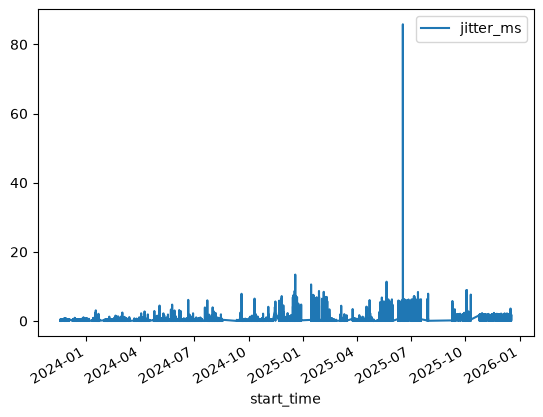

In [10]:
df = df.sort_values(by="start_time")

df.plot(x="start_time", y="jitter_ms")


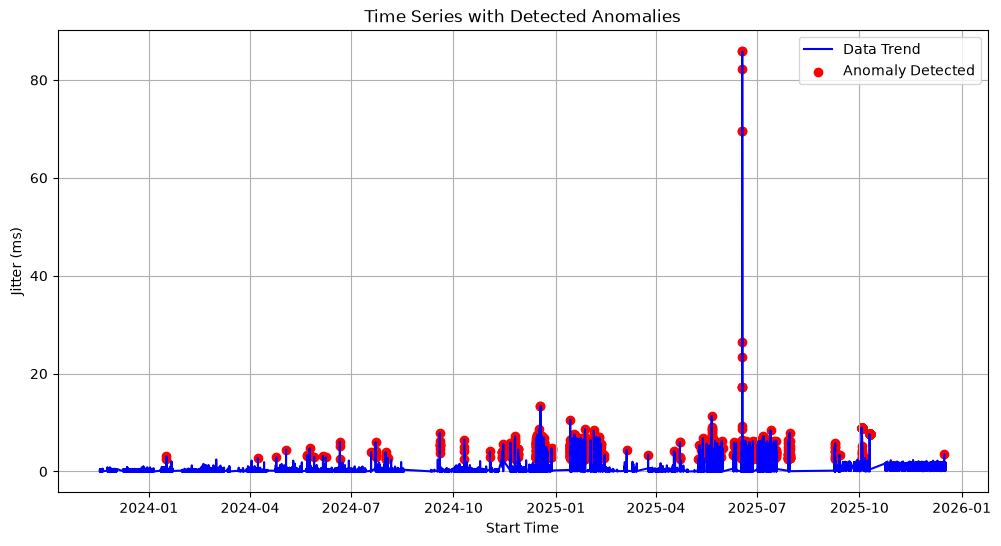

In [45]:
from sklearn.ensemble import IsolationForest

model = IsolationForest(n_estimators=200, contamination=0.01, random_state=42)
X = df["jitter_ms"].values.reshape(-1,1)
model.fit(X)
anomaly_labels = (model.score_samples(X) < -0.75).astype(int)
df['anomaly_label'] = anomaly_labels


plt.figure(figsize=(12, 6)) 

plt.plot(df["start_time"], df["jitter_ms"], label='Data Trend', color='blue')

anomalies_df = df[df['anomaly_label'] == 1]

if not anomalies_df.empty:
    plt.scatter(
        x=anomalies_df["start_time"], 
        y=anomalies_df["jitter_ms"], 
        color='red',         
        label='Anomaly Detected'
    )

# Add essential context to your plot
plt.xlabel("Start Time")
plt.ylabel("Jitter (ms)")
plt.title("Time Series with Detected Anomalies")
plt.legend() 
plt.grid(True)
plt.show()

In [33]:
model = IsolationForest(n_estimators=200, contamination="auto", random_state=42)
model.fit(X)
anomaly_labels = model.score_samples(X)< -0.25
anomaly_labels.astype(int)

array([1, 1, 1, ..., 1, 1, 1], shape=(137551,))